In [1]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

In [2]:
import os
import sys
import json
import logging

import torch
import transformers

from rich.console import Console
from rich.theme import Theme

from src.utils import logging_utils

os.environ["TOKENIZERS_PARALLELISM"] = "false"
os.environ["CUDA_VISIBLE_DEVICES"] = "2,3,4"

custom_theme = Theme({"default": "white"})
console = Console(theme=custom_theme, highlight=False)

def rich_print(*args, **kwargs):
    console.print(*args, **kwargs)

logging.basicConfig(
    level=logging.INFO,
    format=logging_utils.DEFAULT_FORMAT,
    datefmt=logging_utils.DEFAULT_DATEFMT,
    stream=sys.stdout,
)
logger = logging.getLogger(__name__)
logger.info(f"{torch.__version__=}, {torch.version.cuda=}")
logger.info(f"{transformers.__version__=}")

2026-06-01 13:19:30 __main__ INFO     torch.__version__='2.10.0+cu128', torch.version.cuda='12.8'
2026-06-01 13:19:30 __main__ INFO     transformers.__version__='5.3.0'


In [3]:
from src.models import ModelandTokenizer

MODEL_NAME = "Qwen/Qwen2.5-Coder-32B-Instruct"

mt = ModelandTokenizer(
    model_key=MODEL_NAME,
    dtype=torch.bfloat16,
    device_map="auto",
    attn_implementation="eager",
)
print(f"n_layer={mt.n_layer}, n_embd={mt.n_embd}, n_heads={mt.model.config.num_attention_heads}")

2026-06-01 13:19:34 src.models WARNING  Qwen/Qwen2.5-Coder-32B-Instruct not found in /disk/u/arnab/Codes/Models
If not found in cache, model will be downloaded from HuggingFace to cache directory
2026-06-01 13:19:34 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-01 13:19:34 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/config.json "HTTP/1.1 200 OK"
2026-06-01 13:19:34 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/tokenizer_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-01 13:19:34 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/tokenizer_config.json "HTTP/1.1 200 OK"
2026-06-01 13:19:34 httpx INFO     HTT

Loading weights:   0%|          | 0/771 [00:00<?, ?it/s]

2026-06-01 13:19:55 httpx INFO     HTTP Request: HEAD https://huggingface.co/Qwen/Qwen2.5-Coder-32B-Instruct/resolve/main/generation_config.json "HTTP/1.1 307 Temporary Redirect"
2026-06-01 13:19:55 httpx INFO     HTTP Request: HEAD https://huggingface.co/api/resolve-cache/models/Qwen/Qwen2.5-Coder-32B-Instruct/381fc969f78efac66bc87ff7ddeadb7e73c218a7/generation_config.json "HTTP/1.1 200 OK"
2026-06-01 13:19:55 src.models INFO     loaded model <Qwen/Qwen2.5-Coder-32B-Instruct> | size: 62492.135 MB | dtype: torch.bfloat16 | device: cuda:0
n_layer=64, n_embd=5120, n_heads=40


In [4]:
from src.goals.head_loc_attn import HeadMask
from src.utils import env_utils

MASK_PATH = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    f"localization/{MODEL_NAME.split('/')[-1]}/head_mask.pt",
)

ckpt = torch.load(MASK_PATH, map_location="cpu")
print(f"Loaded checkpoint from {MASK_PATH}")
# print(f"  Trained for {ckpt['config']['n_epochs']} epochs  |  N={ckpt['config']['n_instances']} instances")
# print(f"  λ_sparse={ckpt['config']['lambda_sparse']}  lr={ckpt['config']['lr']}")

# Reconstruct mask object
LAYERS = ckpt["layers"]
n_layers_tested = len(LAYERS)
n_heads = ckpt["mask_values"].shape[1]
goalscope_mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    goalscope_mask.values.copy_(ckpt["mask_values"])
    if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
        goalscope_mask.values[0:25] = 0  # zero out early layers
        goalscope_mask.values[56:] = 0  # zero out late layers
    if mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
        goalscope_mask.values[0:18] = 0  # zero out early layers
        goalscope_mask.values[45:] = 0  # zero out late layers

threshold = 0.9
goalscope_heads = goalscope_mask.selected_heads(LAYERS, threshold=threshold)
print(
    f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)"
)
print(f"  Active heads (mask > {threshold}): {len(goalscope_heads)}")
print(f"  Selected heads: {goalscope_heads}")

_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
goalscope_binary_mask = HeadMask(_n_lt, _n_h)
with torch.no_grad():
    goalscope_binary_mask.values.zero_()
    for _layer_idx, _head_idx in goalscope_heads:
        goalscope_binary_mask.values[LAYERS.index(_layer_idx), _head_idx] = 1.0

print(
    f"Binary mask: {goalscope_binary_mask.n_active()} active heads / {_n_lt * _n_h} total heads "
    f"({100 * goalscope_binary_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)

Loaded checkpoint from /disk/u/arnab/Codes/Projects/goals/results/localization/Qwen2.5-Coder-32B-Instruct/head_mask.pt

  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.9): 122
  Selected heads: [(28, 13), (29, 17), (29, 18), (30, 8), (30, 25), (30, 35), (31, 18), (31, 32), (32, 3), (32, 13), (34, 25), (34, 30), (34, 33), (35, 13), (35, 39), (37, 13), (37, 15), (38, 0), (38, 2), (39, 4), (39, 8), (39, 9), (39, 14), (39, 31), (39, 32), (39, 34), (40, 2), (40, 8), (40, 11), (40, 14), (40, 32), (40, 34), (41, 6), (41, 9), (41, 12), (41, 13), (42, 39), (43, 5), (43, 8), (43, 13), (43, 30), (44, 12), (44, 13), (44, 14), (44, 18), (44, 38), (45, 15), (45, 17), (45, 18), (45, 21), (45, 22), (45, 31), (45, 32), (45, 33), (45, 34), (46, 1), (46, 4), (46, 7), (46, 8), (46, 9), (46, 18), (46, 19), (46, 20), (46, 25), (46, 26), (46, 35), (47, 5), (47, 6), (47, 7), (47, 8), (47, 18), (47, 19), (47, 23), (47, 30), (47, 32), (47, 35), (47, 39), (48, 25), (48, 26), (48, 28), (48, 29

In [5]:
import numpy as np
import matplotlib.pyplot as plt

filter_head_path = optimized_path = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "filter",
    mt.name.split("/")[-1],
    "distinct_options/select_one/legacy/epoch_5.npz"
)

filter_results_raw = np.load(optimized_path, allow_pickle=True)
# plt.plot(optimization_results["losses"])
# plt.show()

filter_mask = HeadMask(n_layers_tested, n_heads)
with torch.no_grad():
    filter_mask.values.copy_(torch.tensor(filter_results_raw["optimal_mask"]).to(torch.float32))
    # if mt.name.split("/")[-1] == "Qwen2.5-Coder-32B-Instruct":
    #     filter_mask.values[0:25] = 0  # zero out early layers
    #     filter_mask.values[56:] = 0  # zero out late layers
    # if mt.name.split("/")[-1] == "Llama-3.3-70B-Instruct":
    #     filter_mask.values[0:18] = 0  # zero out early layers
    #     filter_mask.values[45:] = 0  # zero out late layers


threshold = 0.9
filter_heads = filter_mask.selected_heads(LAYERS, threshold=threshold)
print(
    f"\n  Layers: {LAYERS[0]}–{LAYERS[-1]}  ({n_layers_tested} tested, {n_heads} heads each)"
)
print(f"  Active heads (mask > {threshold}): {len(filter_heads)}")
print(f"  Selected heads: {filter_heads}")

_n_lt = len(LAYERS)
_n_h = mt.config.num_attention_heads
filter_binary_mask = HeadMask(_n_lt, _n_h)
with torch.no_grad():
    filter_binary_mask.values.zero_()
    for _layer_idx, _head_idx in filter_heads:
        filter_binary_mask.values[LAYERS.index(_layer_idx), _head_idx] = 1.0

print(
    f"Binary mask: {filter_binary_mask.n_active()} active heads / {_n_lt * _n_h} total heads "
    f"({100 * filter_binary_mask.n_active() / (_n_lt * _n_h):.2f}%)"
)


  Layers: 0–63  (64 tested, 40 heads each)
  Active heads (mask > 0.9): 54
  Selected heads: [(45, 11), (45, 21), (45, 34), (46, 18), (47, 19), (47, 31), (47, 37), (48, 0), (48, 4), (48, 8), (48, 26), (48, 30), (48, 32), (48, 33), (48, 34), (49, 2), (49, 3), (49, 4), (49, 16), (49, 33), (50, 6), (50, 16), (50, 18), (50, 25), (50, 28), (50, 29), (50, 36), (50, 37), (51, 30), (51, 33), (52, 10), (52, 12), (52, 17), (52, 20), (52, 21), (52, 22), (52, 24), (52, 32), (52, 36), (53, 4), (54, 33), (54, 35), (55, 0), (55, 20), (55, 23), (55, 25), (55, 27), (55, 31), (56, 35), (58, 7), (58, 21), (58, 23), (59, 30), (62, 12)]
Binary mask: 54 active heads / 2560 total heads (2.11%)


goalscope: 122 | filter: 54 | overlap: 17


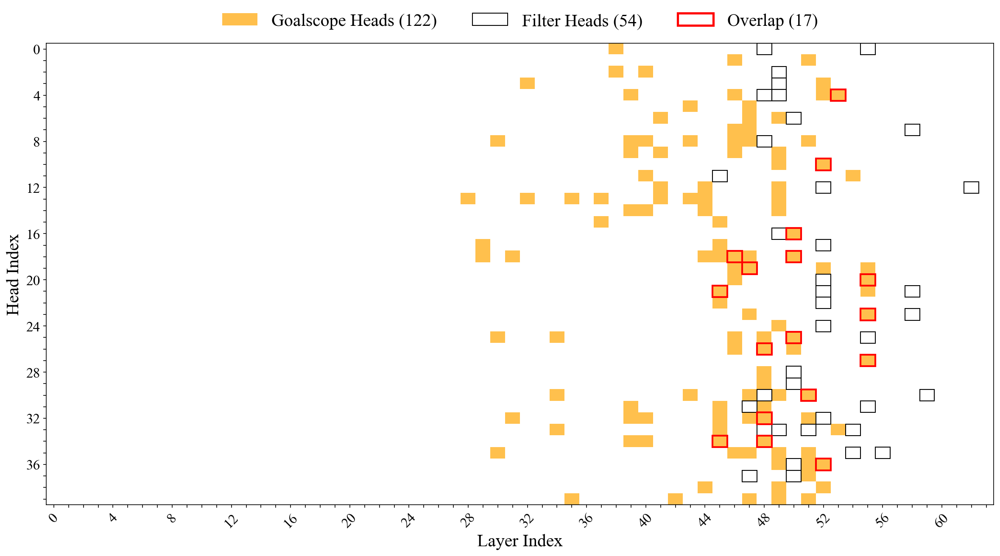

In [6]:
### Visualize overlap — analog of filter/001_make_figures.ipynb

import matplotlib.pyplot as plt
import matplotlib.patches as patches
import matplotlib.patches as mpatches
from matplotlib.colors import LinearSegmentedColormap


def get_ticks(ticks, skip=5):
    return [str(i) if i % skip == 0 else "" for i in ticks]


n_layer = mt.n_layer
n_heads = mt.model.config.num_attention_heads

gs_set = set(goalscope_heads)
fl_set = set(filter_heads)
overlap = list(gs_set & fl_set)
print(f"goalscope: {len(gs_set)} | filter: {len(fl_set)} | overlap: {len(overlap)}")

goalscope_mask_arr = torch.zeros((n_heads, n_layer), dtype=torch.float32)
for layer_idx, head_idx in goalscope_heads:
    goalscope_mask_arr[head_idx, layer_idx] = 1.0

plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 16
MEDIUM_SIZE = 20
BIGGER_SIZE = 24

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)
plt.rc("legend", fontsize=SMALL_SIZE)
plt.rc("figure", titlesize=BIGGER_SIZE)

fig, ax = plt.subplots(figsize=(16, 9))

cmap = LinearSegmentedColormap.from_list("white_orange", ["white", "orange"], N=100)
ax.imshow(goalscope_mask_arr.numpy(), cmap=cmap, aspect="auto", vmin=0, vmax=1, alpha=0.7)

for layer_idx, head_idx in filter_heads:
    ax.add_patch(
        patches.Rectangle(
            (layer_idx - 0.5, head_idx - 0.5),
            1, 1,
            linewidth=1.0,
            edgecolor="black",
            facecolor="none",
        )
    )

for layer_idx, head_idx in overlap:
    ax.add_patch(
        patches.Rectangle(
            (layer_idx - 0.5, head_idx - 0.5),
            1, 1,
            linewidth=2.0,
            edgecolor="red",
            facecolor="none",
        )
    )

plt.xlabel("Layer Index")
plt.ylabel("Head Index")
plt.xticks(ticks=range(n_layer), labels=get_ticks(range(n_layer), skip=4), rotation=45)
plt.yticks(ticks=range(n_heads), labels=get_ticks(range(n_heads), skip=4))

legend_elements = [
    mpatches.Patch(facecolor="orange", alpha=0.7, label=f"Goalscope Heads ({len(gs_set)})"),
    mpatches.Patch(facecolor="white", edgecolor="black", linewidth=1, label=f"Filter Heads ({len(fl_set)})"),
    mpatches.Patch(facecolor="white", edgecolor="red", linewidth=2.5, label=f"Overlap ({len(overlap)})"),
]
ax.legend(
    handles=legend_elements,
    loc="upper center",
    bbox_to_anchor=(0.5, 1.10),
    ncol=3,
    fontsize=MEDIUM_SIZE,
    frameon=False,
)

plt.tight_layout()
plt.show()

In [78]:
from src.goals.data import IncompleteCodeSample
from src.goals.functional import supports_chat_template, apply_chat_template
from src.goals.goalscope import greedy_continue
from rich.markup import escape
from src.tokens import prepare_input
from src.goals.multistep_data import MultiStepDataset

def get_prompt(sample, mt=mt):
    if supports_chat_template(mt):
        prompt = apply_chat_template(
            mt,
            user_query=sample.full_instruction.strip(),
            incomplete_code=sample.code,
        )
    else:
        prompt = sample.code
    return prompt

# test_samples = [
#     IncompleteCodeSample(
#         instruction="""Write a python code that does the following:
# 1. reads a .json file from a give local file path. the json file contains a list of objects.
# 2. indexes the objects in the json file by a specific key for fast retrieval.
# 3. given a target value, retrieves the corresponding object from the indexed data and returns it. time complexity of retrival should be O(log N) or better. 
# 4. make sure to handle error cases, such as when the target value is not found in the indexed data.
# 5. take user inputs, from the terminal, for the target value. assume multiple queries will be made.

# Write your code in a modular way, with clear function definitions.
# Do not add any comments or docstrings. Only provide the code.""",
#         code="",
#         unit_tests=[],
#         function_name="",
#         prefills=[],
#         augmentation=None,
#     ),
# ]

# test_sample = test_samples[-1]
# test_prompt = get_prompt(test_sample, mt)

ds = MultiStepDataset.load_dataset()
test_sample = ds.samples[4]
test_sample.without_comments = True
test_sample.modularity = "modular"

test_prompt = get_prompt(test_sample, mt)

print(test_prompt)

test_gen = greedy_continue(
    mt,
    **prepare_input(prompts=test_prompt, tokenizer=mt),
    max_new_tokens=512,
)
rich_print(f"[white]{escape(test_prompt)}[/white][sea_green3]{escape(test_gen)}[/sea_green3]")

2026-06-01 16:38:36 src.goals.multistep_data INFO     loaded MultiStepDataset: 106 samples from /disk/u/arnab/Codes/Projects/goals/data/multistep/seed.json
<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a python code that does the following:

1. Read a file of one number per line and return a list of floats.
2. Bucket the numbers into n_bins equal-width bins between the min and max value, and return a list of counts per bin.
3. Format the counts as ASCII bars where each '#' represents a fixed number of items.
4. Read a file path and n_bins from the command line, then print the histogram.

Implement each of the above steps as its own well-defined function.
Write your code without any comments or explanations, just the implementation.<|im_end|>
<|im_start|>assistant
<code>



<|im_start|>system
You are a helpful assistant proficient in programming. When completing code, ensure proper syntax and logical 
correctness. Make sure to have all codes inside the <code> </code> tags.<|im_end|>
<|im_start|>user
Write a python code that does the following:

1. Read a file of one number per line and return a list of floats.
2. Bucket the numbers into n_bins equal-width bins between the min and max value, and return a list of counts per 
bin.
3. Format the counts as ASCII bars where each '#' represents a fixed number of items.
4. Read a file path and n_bins from the command line, then print the histogram.

Implement each of the above steps as its own well-defined function.
Write your code without any comments or explanations, just the implementation.<|im_end|>
<|im_start|>assistant
<code>
import sys

def read_numbers(file_path):
    with open(file_path, 'r') as file:
        return [float(line.strip()) for line in file]

def bucket_numbers(numbers, n_bins):
    min_val, max_val = min(numbers), max(numbers)
    bin_width = (max_val - min_val) / n_bins
    bins = [0] * n_bins
    for number in numbers:
        bin_index = int((number - min_val) / bin_width)
        if bin_index == n_bins:  # Handle the edge case where number == max_val
            bin_index -= 1
        bins[bin_index] += 1
    return bins

def format_histogram(bins, scale=5):
    return ['#' * int(count / scale) for count in bins]

def main():
    file_path, n_bins = sys.argv[1], int(sys.argv[2])
    numbers = read_numbers(file_path)
    bins = bucket_numbers(numbers, n_bins)
    histogram = format_histogram(bins)
    for bar in histogram:
        print(bar)

if __name__ == "__main__":
    main()
</code>

In [79]:
full_prompt = test_prompt + test_gen

In [80]:
### Interactive attention visualization
# Hover over a token to see its attention distribution (aggregated over
# selected_heads) over the previous token positions. Click to pin/unpin.
# value_weighted=True scales each (q, k) by ||v_k|| for actual residual contribution.
#
# Consumes `full_prompt` from the previous cell (prefix + generated_code).

from src.attention import get_attention_matrices, show_interactive_attention
from src.tokens import prepare_input

# Batch the same prompt twice as a smoke-test for batched get_attention_matrices.
tokenized = prepare_input([full_prompt, full_prompt], tokenizer=mt)
attn_infos = get_attention_matrices(tokenized, mt, value_weighted=True)
print(f"Batched: returned {len(attn_infos)} AttentionInformation objects")
attn_info = attn_infos[0]
print(f"  attention_matrices.shape = {attn_info.attention_matrices.shape}")
print(f"  n_tokens = {len(attn_info.tokenized_prompt)}")

out_dir = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR, "interactive_attn", mt.name.split("/")[-1]
)
os.makedirs(out_dir, exist_ok=True)
# out_path = os.path.join(out_dir, "goalscope_clock_multistep.html")

###########################################
selected_heads = goalscope_heads
###########################################

show_interactive_attention(
    attn_info=attn_info,
    selected_heads=selected_heads,
    start_from=2,
    agg="mean",
    normalize="row_max",
    cmap="Blues",
    title=f"Selected heads ({len(selected_heads)}) · value-weighted attention",
    # save_path=out_path,
    height=None,
)
# print(f"Saved → {out_path}")

Batched: returned 2 AttentionInformation objects
  attention_matrices.shape = (64, 40, 405, 405)
  n_tokens = 405


'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>Selected heads (122) · value-weighted attention</title>\n<style>\n #iaviz-bb559596 { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-bb559596 h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-bb559596 .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-bb559596 .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-bb559596 .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-bb559596 .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   margin: 1px 0;\n

## Oracle-based step labeling

For a `(sample, full_prompt, generation)` triple, identify which token range in the
full sequence implements which step.

- `prompt_token_range`: where the step text lives in the prompt (via `find_token_range`).
- `gen_token_range`: where the generated code that implements that step lives
  (via oracle line-range labeling + offset-mapping conversion).

Both ranges are **absolute token indices** into the tokenization of
`combined = full_prompt + generation`.

In [ ]:
# Labeling utilities live in src.goals.multistep_label (also used by
# scripts/clock/build_multistep_clock_data.py).
from src.goals.multistep_label import (
    LabeledGeneration,
    StepLabel,
    label_generation,
)

In [82]:
# ── Demo: label the current (test_sample, test_prompt, test_gen) ─────────────
# Uses `test_sample`, `test_prompt`, `test_gen`, `full_prompt` from earlier cells.

from rich.table import Table
from rich.text import Text

labeled = label_generation(
    mt=mt,
    sample=test_sample,
    full_prompt=test_prompt,
    generation=test_gen,
    use_cache=True,
)

# Tokenize once to display the segments verbatim.
combined = test_prompt + test_gen
enc = mt.tokenizer(combined, return_offsets_mapping=True, add_special_tokens=False)
n_combined_tokens = len(enc["input_ids"])
prompt_token_end = next(
    (j for j, (a, _b) in enumerate(enc["offset_mapping"]) if a >= len(test_prompt)),
    n_combined_tokens,
)

print(f"combined: {n_combined_tokens} tokens · prompt ends at token {prompt_token_end}")
print()

table = Table(title=f"step labeling — {labeled.sample_name}", show_lines=True)
table.add_column("k", justify="right", style="bright_white")
table.add_column("step (truncated)", overflow="fold", max_width=46)
table.add_column("prompt tok", justify="center", style="cyan")
table.add_column("gen line", justify="center", style="yellow")
table.add_column("gen tok", justify="center", style="green")
table.add_column("gen code (truncated)", overflow="fold", max_width=150)

for lbl in labeled.labels:
    step_short = lbl.step_text if len(lbl.step_text) < 80 else lbl.step_text[:77] + "…"
    p_str = f"{lbl.prompt_token_range[0]}–{lbl.prompt_token_range[1]}" if lbl.prompt_token_range else "—"
    line_str = f"{lbl.gen_line_range[0]}–{lbl.gen_line_range[1]}" if lbl.gen_line_range else "—"
    tok_str = f"{lbl.gen_token_range[0]}–{lbl.gen_token_range[1]}" if lbl.gen_token_range else "—"
    code_short = lbl.gen_code.replace("\n", "↵\n").strip()
    if len(code_short) > 200:
        code_short = code_short[:197] + "…"
    table.add_row(str(lbl.step_idx), step_short, p_str, line_str, tok_str, code_short)

console.print(table)

# Sanity check: re-decode each gen_token_range from the combined tokenization.
print("\n=== Sanity: decoded segments by gen_token_range ===")
input_ids = enc["input_ids"]
for lbl in labeled.labels:
    if lbl.gen_token_range is None:
        print(f"  step {lbl.step_idx}: [no implementation found]")
        continue
    s, e = lbl.gen_token_range
    decoded = mt.tokenizer.decode(input_ids[s:e])
    snippet = decoded.replace("\n", "↵\n")
    if len(snippet) > 200:
        snippet = snippet[:197] + "…"
    print(f"  step {lbl.step_idx} ({s}:{e}): {snippet}")

combined: 405 tokens · prompt ends at token 168



                                          step labeling — ascii_histogram                                          
┏━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━┳━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ k ┃ step (truncated)                    ┃ prompt tok ┃ gen line ┃ gen tok ┃ gen code (truncated)                ┃
┡━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━╇━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ 0 │ Read a file of one number per line  │   55–70    │   3–5    │ 171–200 │ def read_numbers(file_path):↵       │
│   │ and return a list of floats.        │            │          │         │     with open(file_path, 'r') as    │
│   │                                     │            │          │         │ file:↵                              │
│   │                                     │            │          │         │         return ↵                    │
├───┼─────────────────────────────────────┼────────────┼──────────┼─────────┼─────────────────────────────────────┤
│ 1 │ Bucket the numbers into n_bins      │   72–97    │   7–16   │ 201–308 │ def bucket_numbers(numbers,         │
│   │ equal-width bins between the min    │            │          │         │ n_bins):↵                           │
│   │ and max value…                      │            │          │         │     min_val, max_val =              │
│   │                                     │            │          │         │ min(numbers), max(numbers)↵         │
│   │                                     │            │          │         │     bin_width = (max_val - min_val) │
│   │                                     │            │          │         │ / n_bins↵                           │
│   │                                     │            │          │         │     bins = [0] * n_bins↵            │
│   │                                     │            │          │         │     for number in numbers:↵         │
│   │                                     │            │          │         │         b…                          │
├───┼─────────────────────────────────────┼────────────┼──────────┼─────────┼─────────────────────────────────────┤
│ 2 │ Format the counts as ASCII bars     │   99–115   │  18–19   │ 309–333 │ def format_histogram(bins,          │
│   │ where each '#' represents a fixed   │            │          │         │ scale=5):↵                          │
│   │ number of i…                        │            │          │         │     return ['#' * int(count /       │
│   │                                     │            │          │         │ scale) for count in bins]↵          │
├───┼─────────────────────────────────────┼────────────┼──────────┼─────────┼─────────────────────────────────────┤
│ 3 │ Read a file path and n_bins from    │  117–134   │  21–30   │ 334–402 │ def main():↵                        │
│   │ the command line, then print the    │            │          │         │     file_path, n_bins =             │
│   │ histogram.                          │            │          │         │ sys.argv[1], int(sys.argv[2])↵      │
│   │                                     │            │          │         │     numbers =                       │
│   │                                     │            │          │         │ read_numbers(file_path)↵            │
│   │                                     │            │          │         │     bins = bucket_numbers(numbers,  │
│   │                                     │            │          │         │ n_bins)↵                            │
│   │                                     │            │          │         │     histogram =                     │
│   │                                     │            │          │         │ format_histogram(bins)↵             │
│   │                                     │            │          │         │     fo…                             │
└───┴─────────────────────────────────────┴────────────┴


=== Sanity: decoded segments by gen_token_range ===
  step 0 (171:200): def read_numbers(file_path):↵
    with open(file_path, 'r') as file:↵
        return [float(line.strip()) for line in file
  step 1 (201:308): def bucket_numbers(numbers, n_bins):↵
    min_val, max_val = min(numbers), max(numbers)↵
    bin_width = (max_val - min_val) / n_bins↵
    bins = [0] * n_bins↵
    for number in numbers:↵
        b…
  step 2 (309:333): def format_histogram(bins, scale=5):↵
    return ['#' * int(count / scale) for count in bins
  step 3 (334:402): def main():↵
    file_path, n_bins = sys.argv[1], int(sys.argv[2])↵
    numbers = read_numbers(file_path)↵
    bins = bucket_numbers(numbers, n_bins)↵
    histogram = format_histogram(bins)↵
    fo…


## Visualize cached attention (from `scripts/clock/build_multistep_clock_data.py`)

Loads `completion.json`, `labels.json`, `attn.npz` for a given
`(sample_name, modularity)` and re-uses `show_interactive_attention` over
whichever subset of heads you want (goalscope, filter, union, all, custom).

Cache layout (labeled artifacts and attention are split so downstream code
that doesn't need the heavy attention tensor can iterate over the small JSONs
quickly):
```
results/multistep_clock/<model>/
  <modularity>/<sample_name>/
    completion.json   {sample_name, modularity, prompt, generation}
    labels.json       LabeledGeneration.to_dict()
  attn/<modularity>/<sample_name>/
    attn.npz          {attn: (n_layers, n_heads, seq, seq) float16, tokens}
```

Three loaders:
- `load_labeled_sample(name, mod)` → `(completion, labels)`  (fast, JSON only)
- `load_attn(name, mod)`            → `(attn, tokens)`        (heavy, npz)
- `load_cached_sample(name, mod)`   → all four (combined)

In [96]:
import json
import os

import numpy as np

from src.attention import AttentionInformation, show_interactive_attention
from src.utils import env_utils


def _cache_root(model_short: str | None = None) -> str:
    if model_short is None:
        model_short = mt.name.split("/")[-1]
    return os.path.join(
        env_utils.DEFAULT_RESULTS_DIR, "multistep_clock", model_short
    )


def load_labeled_sample(
    sample_name: str,
    modularity: str,
    model_short: str | None = None,
) -> tuple[dict, dict]:
    """Lightweight: (completion, labels) from the labeled subtree."""
    base = os.path.join(_cache_root(model_short), modularity, sample_name)
    with open(os.path.join(base, "completion.json")) as f:
        completion = json.load(f)
    with open(os.path.join(base, "labels.json")) as f:
        labels = json.load(f)
    return completion, labels


def load_attn(
    sample_name: str,
    modularity: str,
    model_short: str | None = None,
) -> tuple[np.ndarray, list[str]]:
    """Heavy: (attn, tokens) from the attn subtree."""
    base = os.path.join(_cache_root(model_short), "attn", modularity, sample_name)
    with np.load(os.path.join(base, "attn.npz"), allow_pickle=True) as d:
        attn = d["attn"]                  # (n_layers, n_heads, seq, seq) float16
        tokens = list(d["tokens"])
    return attn, tokens


def load_cached_sample(
    sample_name: str,
    modularity: str,
    model_short: str | None = None,
) -> tuple[dict, dict, np.ndarray, list[str]]:
    """Combined: (completion, labels, attn, tokens)."""
    completion, labels = load_labeled_sample(sample_name, modularity, model_short)
    attn, tokens = load_attn(sample_name, modularity, model_short)
    return completion, labels, attn, tokens


def attn_info_from_cache(
    attn: np.ndarray, tokens: list[str]
) -> AttentionInformation:
    """Wrap cached float16 attention + tokens as an AttentionInformation."""
    return AttentionInformation(
        tokenized_prompt=tokens,
        attention_matrices=attn,
    )


# ── Configure ────────────────────────────────────────────────────────────────
CACHED_SAMPLE = "csv_query"
CACHED_MODULARITY = "modular"   # "modular" | "monolithic"
SELECTED_FOR_VIZ = goalscope_heads
# Other options:
#   SELECTED_FOR_VIZ = filter_heads
#   SELECTED_FOR_VIZ = sorted(set(goalscope_heads) | set(filter_heads))

completion, labels, attn_arr, tokens = load_cached_sample(
    CACHED_SAMPLE, CACHED_MODULARITY
)
print(f"sample:        {completion['sample_name']} ({completion['modularity']})")
print(f"tokens:        {len(tokens)}  (prompt+gen)")
print(f"attn:          {attn_arr.shape}  dtype={attn_arr.dtype}")
print(f"steps labeled: {len(labels['labels'])}")

attn_info = attn_info_from_cache(attn_arr, tokens)

# Skip the chat-template prefix so the viz starts at the user query.
start_from = 0
try:
    first_user = next(
        i for i, t in enumerate(tokens) if "user" in t.replace("＜", "<")
    )
    start_from = max(0, first_user - 1)
except StopIteration:
    pass

show_interactive_attention(
    attn_info=attn_info,
    selected_heads=SELECTED_FOR_VIZ,
    start_from=start_from,
    agg="mean",
    normalize="row_max",
    cmap="Blues",
    title=(
        f"{CACHED_SAMPLE} · {CACHED_MODULARITY} · "
        f"{len(SELECTED_FOR_VIZ)} heads (cached)"
    ),
    height=None,
)

sample:        csv_query (modular)
tokens:        382  (prompt+gen)
attn:          (64, 40, 382, 382)  dtype=float16
steps labeled: 4


'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>csv_query · modular · 122 heads (cached)</title>\n<style>\n #iaviz-3466947b { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-3466947b h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-3466947b .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-3466947b .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-3466947b .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-3466947b .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   margin: 1px 0;\n   bord

## Head scores — "step-lookback"

For each attention head, score = pooled mean across (sample, target_step k, query_token q) of:

$$\text{ratio}(L, H, q, k) \;=\; \frac{\sum_{s \in \text{prompt\_range}[k]} A^{L,H}_{q,s}}{\frac{1}{K}\sum_{k'} \sum_{s \in \text{prompt\_range}[k']} A^{L,H}_{q,s}}$$

i.e. **how much more attention does this head pay back to the step k whose code is currently being generated, vs the average step**. Ratio > 1 ⇒ above average.

Scores are computed by `scripts/clock/score_multistep_heads.py` and saved under
`results/multistep_clock/<model>/head_scores/aggregated.npz` with three views:
`modular_score`, `monolithic_score`, `combined_score` — each shape `(n_layers, n_heads)`.

loaded /disk/u/arnab/Codes/Projects/goals/results/multistep_clock/Qwen2.5-Coder-32B-Instruct/head_scores/aggregated.npz
  modular:     mean=1.325  max=2.612
  monolithic:  mean=1.319  max=2.349
  combined:    mean=1.323  max=2.485


/disk/u/arnab/miniconda3/envs/goals/lib/python3.12/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 8658 (\N{RIGHTWARDS DOUBLE ARROW}) missing from font(s) Times New Roman.
  fig.canvas.print_figure(bytes_io, **kw)


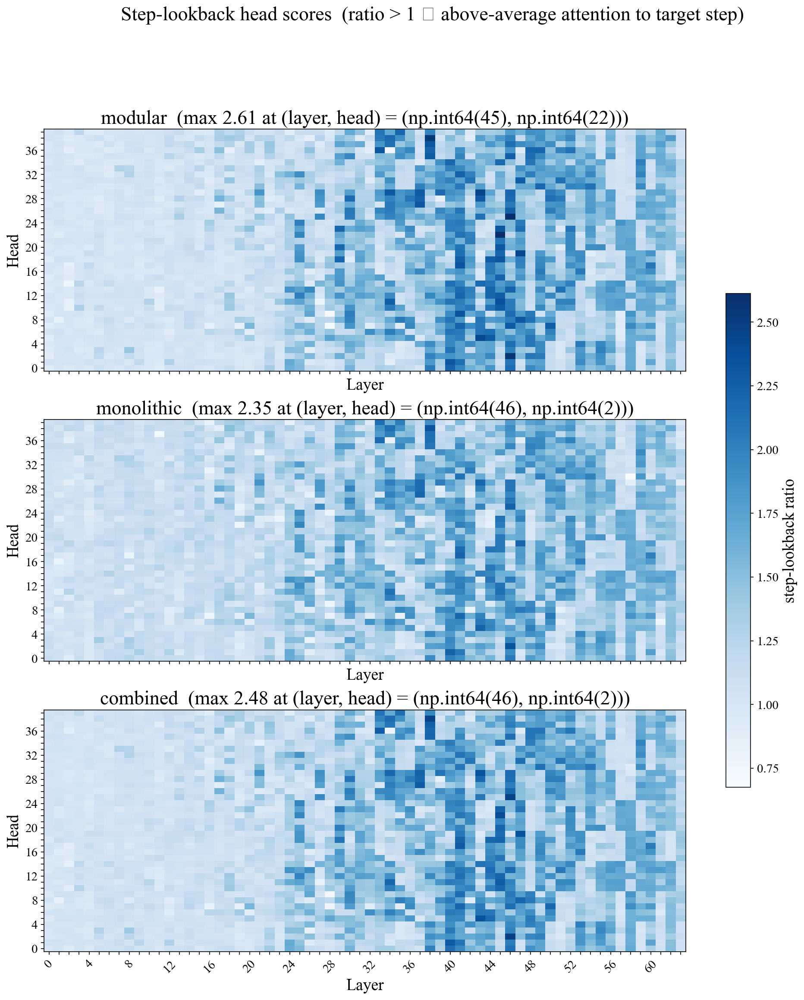

In [97]:
# ── Load aggregated head scores & plot heatmaps ──────────────────────────────
import os
import numpy as np
import matplotlib.pyplot as plt

scores_path = os.path.join(
    env_utils.DEFAULT_RESULTS_DIR,
    "multistep_clock",
    mt.name.split("/")[-1],
    "head_scores",
    "aggregated.npz",
)
agg = np.load(scores_path)
scores_modular = agg["modular_score"]        # (n_layers, n_heads)
scores_monolithic = agg["monolithic_score"]
scores_combined = agg["combined_score"]
print(f"loaded {scores_path}")
print(f"  modular:     mean={scores_modular.mean():.3f}  max={scores_modular.max():.3f}")
print(f"  monolithic:  mean={scores_monolithic.mean():.3f}  max={scores_monolithic.max():.3f}")
print(f"  combined:    mean={scores_combined.mean():.3f}  max={scores_combined.max():.3f}")

panels = [
    ("modular",    scores_modular),
    ("monolithic", scores_monolithic),
    ("combined",   scores_combined),
]
# Shared color scale across panels so they're directly comparable.
vmin = min(s.min() for _, s in panels)
vmax = max(s.max() for _, s in panels)

n_layer_total = scores_combined.shape[0]
n_heads_total = scores_combined.shape[1]

plt.rcParams["figure.dpi"] = 150
plt.rcParams["font.family"] = "Times New Roman"

SMALL_SIZE = 14
MEDIUM_SIZE = 18
BIGGER_SIZE = 22

plt.rc("font", size=SMALL_SIZE)
plt.rc("axes", titlesize=BIGGER_SIZE)
plt.rc("axes", labelsize=MEDIUM_SIZE)
plt.rc("xtick", labelsize=SMALL_SIZE)
plt.rc("ytick", labelsize=SMALL_SIZE)


def get_ticks(ticks, skip=5):
    return [str(i) if i % skip == 0 else "" for i in ticks]


fig, axes = plt.subplots(
    len(panels), 1,
    figsize=(16, 5.5 * len(panels)),
    sharex=True,
)
last_im = None
for ax, (title, scores) in zip(axes, panels):
    im = ax.imshow(
        scores.T,
        aspect="auto",
        cmap="Blues",
        vmin=vmin,
        vmax=vmax,
        interpolation="nearest",
        origin="lower",
    )
    last_im = im
    argmax_lh = tuple(np.unravel_index(scores.argmax(), scores.shape))
    ax.set_title(f"{title}  (max {scores.max():.2f} at (layer, head) = {argmax_lh})")
    ax.set_xlabel("Layer")
    ax.set_ylabel("Head")
    ax.set_xticks(range(n_layer_total))
    ax.set_xticklabels(get_ticks(range(n_layer_total), skip=4), rotation=45)
    ax.set_yticks(range(n_heads_total))
    ax.set_yticklabels(get_ticks(range(n_heads_total), skip=4))

fig.colorbar(
    last_im,
    ax=axes.tolist(),
    shrink=0.6,
    label="step-lookback ratio",
)
fig.suptitle(
    "Step-lookback head scores  (ratio > 1 ⇒ above-average attention to target step)",
    fontsize=BIGGER_SIZE,
    y=0.995,
)
plt.show()

In [99]:
# ── Top-N step-lookback heads → drive the interactive viz ────────────────────
TOP_N = 50
WHICH_SCORE = scores_combined       # try: scores_modular | scores_monolithic | scores_combined

n_layers, n_heads_total = WHICH_SCORE.shape
flat_idx = np.argsort(WHICH_SCORE, axis=None)[::-1][:TOP_N]
step_lookback_heads = [
    (int(layer), int(head))
    for layer, head in (np.unravel_index(i, WHICH_SCORE.shape) for i in flat_idx)
]
top_scores = [float(WHICH_SCORE[layer, head]) for layer, head in step_lookback_heads]

print(f"Top {TOP_N} heads by step-lookback (combined):")
for rank, ((layer, head), s) in enumerate(zip(step_lookback_heads[:20], top_scores[:20]), start=1):
    print(f"  {rank:2d}.  L{layer:2d} H{head:2d}   score={s:.3f}")
if TOP_N > 20:
    print(f"  ... (+ {TOP_N - 20} more)")

# Re-run the cached viz with the discovered heads.
# Adjust CACHED_SAMPLE / CACHED_MODULARITY in the previous viz cell, or override below.
VIZ_SAMPLE = CACHED_SAMPLE if 'CACHED_SAMPLE' in dir() else "csv_query"
VIZ_MODULARITY = CACHED_MODULARITY if 'CACHED_MODULARITY' in dir() else "modular"

completion, labels, attn_arr, tokens = load_cached_sample(VIZ_SAMPLE, VIZ_MODULARITY)
attn_info = attn_info_from_cache(attn_arr, tokens)

start_from = 0
try:
    first_user = next(i for i, t in enumerate(tokens) if "user" in t.replace("＜", "<"))
    start_from = max(0, first_user - 1)
except StopIteration:
    pass

show_interactive_attention(
    attn_info=attn_info,
    selected_heads=step_lookback_heads,
    start_from=start_from,
    agg="mean",
    normalize="row_max",
    cmap="Blues",
    title=f"{VIZ_SAMPLE} · {VIZ_MODULARITY} · top-{TOP_N} step-lookback heads",
    height=None,
)

Top 50 heads by step-lookback (combined):
   1.  L46 H 2   score=2.485
   2.  L38 H38   score=2.465
   3.  L46 H25   score=2.463
   4.  L45 H22   score=2.398
   5.  L47 H19   score=2.353
   6.  L43 H 5   score=2.345
   7.  L43 H29   score=2.343
   8.  L41 H17   score=2.295
   9.  L40 H 1   score=2.284
  10.  L37 H27   score=2.281
  11.  L45 H11   score=2.274
  12.  L33 H36   score=2.265
  13.  L38 H37   score=2.260
  14.  L45 H23   score=2.244
  15.  L37 H29   score=2.234
  16.  L45 H18   score=2.225
  17.  L41 H18   score=2.221
  18.  L45 H20   score=2.218
  19.  L45 H12   score=2.216
  20.  L41 H 7   score=2.215
  ... (+ 30 more)


'<!DOCTYPE html>\n<html><head><meta charset="utf-8"><title>csv_query · modular · top-50 step-lookback heads</title>\n<style>\n #iaviz-3efb9693 { font-family: -apple-system, BlinkMacSystemFont, "Segoe UI", Roboto, Helvetica, Arial, sans-serif;\n            background: #fafafa; color: #111; padding: 12px; border-radius: 6px; }\n #iaviz-3efb9693 h2 { margin: 4px 0 6px 0; font-size: 16px; font-weight: 600; color: #111; }\n #iaviz-3efb9693 .meta { color: #555; font-size: 12px; margin-bottom: 10px; }\n #iaviz-3efb9693 .head-list { color: #777; font-size: 11px; margin-bottom: 14px; font-family: monospace; }\n #iaviz-3efb9693 .tokens {\n   font-family: ui-monospace, "SF Mono", Menlo, Consolas, monospace;\n   font-size: 13px;\n   line-height: 1.85;\n   background: #fff;\n   border: 1px solid #ddd;\n   border-radius: 6px;\n   padding: 14px 16px;\n   white-space: pre-wrap;\n   word-break: break-word;\n }\n #iaviz-3efb9693 .tok {\n   display: inline-block;\n   padding: 2px 4px;\n   margin: 1px 0;\

ok. I don't see a consistent attention pattern, or a sparse set of attention heads that always *look back* to the instruction of the relevant step.

Let's try learning a probe to detect the *commitment region*.
*Commitment region*: Tokens where the model *"commits"* to a *"some"* step k. 
At certain positions the LM needs to commit to some step k. In our hypothesis, this is a very discrete signal: the first few tokens of *some* decision/step/instruction. We have labelled code-spans that does one very specific thing. My hypothesis is that at the beginning of those spans, this signal should be very strong. And in the middle tokens, the signal should be much weaker, as the commitment just persists at those tokens but doesn't need to be re-asserted.

Let's validate this hypothesis by learning a probe with the contrastive objective we explored in the 16_mining_recursion.ipynb notebook. Brainstorm with me on setting up this experiment.